# Setup

In [1]:
# from google.colab import files
# files.upload()

!pip install kagglehub


In [2]:
import kagglehub
from google.colab import userdata
import os
os.environ["KAGGLE_USERNAME"] = userdata.get('KAGGLE_USERNAME')
os.environ["KAGGLE_KEY"] = userdata.get('KAGGLE_KEY')

path = kagglehub.dataset_download("yash92328/ai4mars-terrainaware-autonomous-driving-on-mars")
print(path)

Using Colab cache for faster access to the 'ai4mars-terrainaware-autonomous-driving-on-mars' dataset.
/kaggle/input/ai4mars-terrainaware-autonomous-driving-on-mars


In [3]:
import glob

MSL = glob.glob(os.path.join(path, "**", "msl"), recursive=True)[0]
print("msl folder:", MSL)

EDR_DIR = os.path.join(MSL, "images", "edr")
MXY_DIR = os.path.join(MSL, "images", "mxy")
RNG_DIR = os.path.join(MSL, "images", "rng-30m")
TRAIN_LABEL_DIR = os.path.join(MSL, "labels", "train")
print(os.listdir(os.path.join(MSL, "labels", "test")))

msl folder: /kaggle/input/ai4mars-terrainaware-autonomous-driving-on-mars/ai4mars-dataset-merged-0.1/msl
['masked-gold-min3-100agree', 'masked-gold-min2-100agree', 'masked-gold-min1-100agree']


In [4]:
TEST_LABEL_DIR = os.path.join(MSL, "labels", "test", "masked-gold-min3-100agree")

for name, d in [("edr", EDR_DIR), ("mxy", MXY_DIR), ("rng", RNG_DIR),
                ("train labels", TRAIN_LABEL_DIR), ("test labels", TEST_LABEL_DIR)]:
    files = sorted(os.listdir(d))
    print(f"{name}: {len(files)} files, e.g. {files[:2]}")

edr: 18130 files, e.g. ['NLA_397586928EDR_F0010008AUT_04096M1.JPG', 'NLA_397586934EDR_F0010008AUT_04096M1.JPG']
mxy: 18097 files, e.g. ['NLA_397586928MXY_F0010008AUT_04096M1.png', 'NLA_397586934MXY_F0010008AUT_04096M1.png']
rng: 18096 files, e.g. ['NLA_397586928RNG_F0010008AUT_04096M1.png', 'NLA_397586934RNG_F0010008AUT_04096M1.png']
train labels: 16064 files, e.g. ['NLA_397586934EDR_F0010008AUT_04096M1.png', 'NLA_397681339EDR_F0020000AUT_04096M1.png']
test labels: 322 files, e.g. ['NLA_409036068EDR_F0051606NCAM00348M1_merged.png', 'NLA_409036116EDR_F0051606NCAM00348M1_merged.png']


# Task #1: Random sample

In [5]:
import random

train_labels = sorted(f for f in os.listdir(TRAIN_LABEL_DIR) if f.endswith(".png"))
test_labels = sorted(f for f in os.listdir(TEST_LABEL_DIR) if f.endswith(".png"))

random.seed(42)
train_sample = random.sample(train_labels, 500)
test_sample = random.sample(test_labels, 125)

print(len(train_sample), "train", len(test_sample), "test")
print(train_sample[:3])
print(test_sample[:3])

500 train 125 test
['NLB_532342701EDR_F0592578NCAM00279M1.png', 'NLB_424934381EDR_F0060658NCAM00247M1.png', 'NLA_402816098EDR_F0050104NCAM00451M1.png']
['NLB_520358689EDR_F0550940NCAM00299M1_merged.png', 'NLB_436384026EDR_F0211362NCAM00279M1_merged.png', 'NLB_463814218EDR_F0420000NCAM00354M1_merged.png']


In [6]:
# Making sure we get the right amount of files, no duplicates, and that all the files are real train files

print(len(train_sample) == 500, len(test_sample) == 125) # checks if file amount is right
print(len(set(train_sample)) == 500) # checks for duplicates
print(all(f in train_labels for f in train_sample)) # checks if all train files are real

True True
True
True


# Task #2: Check files, sizes, and label values

In [7]:
def get_paths(label_file, split):
  """Given a label file name, return the paths to its photo, masks, and label."""
  base = label_file.replace(".png", "")
  if split == "test":
    base = base.replace("_merged", "")
    label_dir = TEST_LABEL_DIR
  else:
    label_dir = TRAIN_LABEL_DIR

  return {
      "edr":   os.path.join(EDR_DIR, base + ".JPG"),
      "mxy":   os.path.join(MXY_DIR, base.replace("EDR", "MXY") + ".png"),
      "rng":   os.path.join(RNG_DIR, base.replace("EDR", "RNG") + ".png"),
      "label": os.path.join(label_dir, label_file),
  }

print(get_paths(train_sample[0], "train"))
print(get_paths(test_sample[0], "test"))

{'edr': '/kaggle/input/ai4mars-terrainaware-autonomous-driving-on-mars/ai4mars-dataset-merged-0.1/msl/images/edr/NLB_532342701EDR_F0592578NCAM00279M1.JPG', 'mxy': '/kaggle/input/ai4mars-terrainaware-autonomous-driving-on-mars/ai4mars-dataset-merged-0.1/msl/images/mxy/NLB_532342701MXY_F0592578NCAM00279M1.png', 'rng': '/kaggle/input/ai4mars-terrainaware-autonomous-driving-on-mars/ai4mars-dataset-merged-0.1/msl/images/rng-30m/NLB_532342701RNG_F0592578NCAM00279M1.png', 'label': '/kaggle/input/ai4mars-terrainaware-autonomous-driving-on-mars/ai4mars-dataset-merged-0.1/msl/labels/train/NLB_532342701EDR_F0592578NCAM00279M1.png'}
{'edr': '/kaggle/input/ai4mars-terrainaware-autonomous-driving-on-mars/ai4mars-dataset-merged-0.1/msl/images/edr/NLB_520358689EDR_F0550940NCAM00299M1.JPG', 'mxy': '/kaggle/input/ai4mars-terrainaware-autonomous-driving-on-mars/ai4mars-dataset-merged-0.1/msl/images/mxy/NLB_520358689MXY_F0550940NCAM00299M1.png', 'rng': '/kaggle/input/ai4mars-terrainaware-autonomous-drivin

In [8]:
import numpy as np
from PIL import Image

ALLOWED = {0, 1, 2, 3, 255}

def check(label_file, split):
  """Return a list of problems with this image. An empty list means it passed."""
  paths = get_paths(label_file, split)

  # First check to make sure all the files exist
  problems = []
  for kind, p in paths.items():
    if not os.path.exists(p):
      problems.append(f"missing {kind}")
  if problems:
    return problems

  # Second check to mae sure all four are hte same size
  sizes = {kind: Image.open(p).size for kind, p in paths.items()}
  if len(set(sizes.values())) > 1:
    problems.append(f"size mismatch {sizes}")

  # Third check to make sure that the label only uses allowed values
  label = np.array(Image.open(paths["label"]))
  bad = set(np.unique(label).tolist()) - ALLOWED
  if bad:
    problems.append(f"bad label values {bad}")

  return problems

print(check(train_sample[0], "train"))

[]


In [9]:
# Just making sure checker can actually fail
print(check("NLA_FAKE123EDR_TEST.png", "train"))

['missing edr', 'missing mxy', 'missing rng', 'missing label']


In [10]:
results = []
for split, sample in [("train", train_sample), ("test", test_sample)]:
  for f in sample:
    results.append({"split": split, "label_file": f, "problems": check(f, split)})

failed = [r for r in results if r["problems"]]
print(f"{len(failed)} of {len(results)} images failed")
for r in failed:
  print(r["split"], r["label_file"], r["problems"])

0 of 625 images failed


In [11]:
import pandas as pd

rows = []
for r in results:
  paths = get_paths(r["label_file"], r["split"])
  row = {"split": r["split"]}
  for kind, p in paths.items():
    row[kind] = os.path.relpath(p, MSL)
  row["passed"] = len(r["problems"]) == 0
  rows.append(row)

df = pd.DataFrame(rows)
df.to_csv("sample_split.csv", index=False)
print(df.shape)
df.head()

(625, 6)


,split,edr,mxy,rng,label,passed
0,train,images/edr/NLB_532342701EDR_F0592578NCAM00279M...,images/mxy/NLB_532342701MXY_F0592578NCAM00279M...,images/rng-30m/NLB_532342701RNG_F0592578NCAM00...,labels/train/NLB_532342701EDR_F0592578NCAM0027...,True
1,train,images/edr/NLB_424934381EDR_F0060658NCAM00247M...,images/mxy/NLB_424934381MXY_F0060658NCAM00247M...,images/rng-30m/NLB_424934381RNG_F0060658NCAM00...,labels/train/NLB_424934381EDR_F0060658NCAM0024...,True
2,train,images/edr/NLA_402816098EDR_F0050104NCAM00451M...,images/mxy/NLA_402816098MXY_F0050104NCAM00451M...,images/rng-30m/NLA_402816098RNG_F0050104NCAM00...,labels/train/NLA_402816098EDR_F0050104NCAM0045...,True
3,train,images/edr/NLB_550280573EDR_F0633092NCAM00312M...,images/mxy/NLB_550280573MXY_F0633092NCAM00312M...,images/rng-30m/NLB_550280573RNG_F0633092NCAM00...,labels/train/NLB_550280573EDR_F0633092NCAM0031...,True
4,train,images/edr/NLB_454665258EDR_F0331036NCAM00293M...,images/mxy/NLB_454665258MXY_F0331036NCAM00293M...,images/rng-30m/NLB_454665258RNG_F0331036NCAM00...,labels/train/NLB_454665258EDR_F0331036NCAM0029...,True


**Result:** 0 of 625 sampled images failed. All have edr/mxy/rng/label files, matching sizes, and only label values {0, 1, 2, 3, 255}.

Note: the full dataset has 33 photos missing MXY masks and 34 missing RNG masks, but none landed in this sample.

# Task #3: Check images, create threshold

In [12]:
# hey guys
import matplotlib.pyplot as plt

NULL_VALUE = 255

def labeled_fraction(label_file, split):
  """Return the fraction of pixels in a label that are NOT 255 (i.e. labeled)."""
  paths = get_paths(label_file, split)
  label = np.array(Image.open(paths["label"]))
  return (label != NULL_VALUE).sum() / label.size

# Test it on one image before running everything
# print(labeled_fraction(train_sample[0], "train"))

# Add label_file and labeled_frac to the df from Task #2
df["label_file"] = [r["label_file"] for r in results]
df["labeled_frac"] = [labeled_fraction(r["label_file"], r["split"]) for r in results]

print(df.groupby("split")["labeled_frac"].describe())

       count      mean       std  min       25%       50%       75%       max
split                                                                        
test   125.0  0.365718  0.256233  0.0  0.148805  0.353882  0.571998  0.908750
train  500.0  0.541216  0.246395  0.0  0.356939  0.573856  0.746091  0.975905


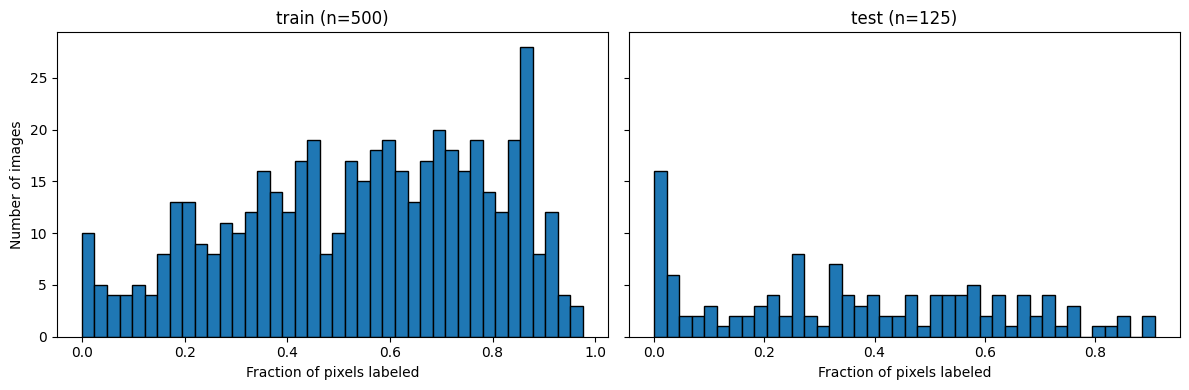

In [13]:
# Plot 1: histogram of labeled fraction

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, split in zip(axes, ["train", "test"]):
  vals = df.loc[df.split == split, "labeled_frac"]
  ax.hist(vals, bins=40, edgecolor="black")
  ax.set_title(f"{split} (n={len(vals)})")
  ax.set_xlabel("Fraction of pixels labeled")
axes[0].set_ylabel("Number of images")
plt.tight_layout()
plt.show()

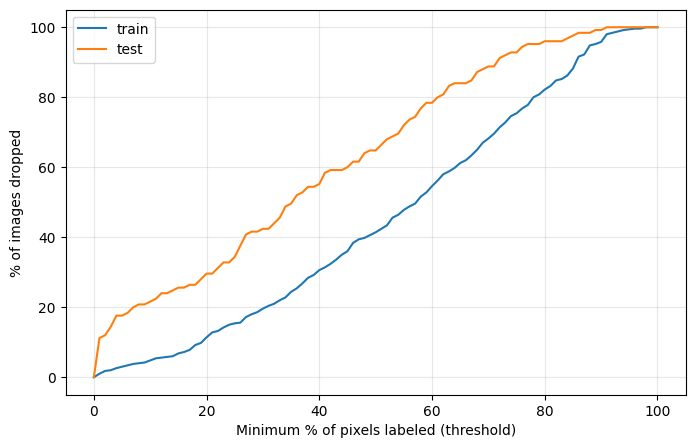

In [14]:
# Plot 2: how many images would each threshold drop?

thresholds = np.linspace(0, 1, 101)

plt.figure(figsize=(8, 5))
for split in ["train", "test"]:
  vals = df.loc[df.split == split, "labeled_frac"].values
  dropped = [(vals < t).mean() * 100 for t in thresholds]
  plt.plot(thresholds * 100, dropped, label=split)

plt.xlabel("Minimum % of pixels labeled (threshold)")
plt.ylabel("% of images dropped")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [15]:
# Apply the threshold

THRESHOLD = 0.10  # may change later

# Keep all test images; only filter train
df["keep"] = (df["split"] == "test") | (df["labeled_frac"] >= THRESHOLD)

print(df.groupby("split")["keep"].agg(kept="sum", total="count"))
print(f"Dropped: {(~df.keep).sum()} of {len(df)}")

df.to_csv("sample_split_filtered.csv", index=False)

df_kept = df[df.keep]
print(df_kept.shape)

       kept  total
split             
test    125    125
train   476    500
Dropped: 24 of 625
(601, 9)


# Task #4: Pixel Count

In [16]:
import os
import glob
import random
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Load the dataset
path = kagglehub.dataset_download(
    "yash92328/ai4mars-terrainaware-autonomous-driving-on-mars"
)
MSL = glob.glob(os.path.join(path, "**", "msl"), recursive=True)[0]
TRAIN_LABEL_DIR = os.path.join(MSL, "labels", "train")
NULL_VALUE = 255

# Use the same 500-image training subset as Task 1
train_labels = sorted(
    f for f in os.listdir(TRAIN_LABEL_DIR) if f.endswith(".png")
)
random.seed(42)
train_sample = random.sample(train_labels, 500)

CLASSES = [0, 1, 2, 3]
CLASS_LABELS = ["soil", "bedrock", "sand", "big rock"]
N = len(train_sample)

pixel_counts = np.zeros(len(CLASSES), dtype=np.int64)
image_counts = np.zeros(len(CLASSES), dtype=np.int64)
heat = None
labeled_total = 0
resized = 0

Using Colab cache for faster access to the 'ai4mars-terrainaware-autonomous-driving-on-mars' dataset.


In [17]:
# Count pixels and images containing each class
for f in train_sample:
  with Image.open(os.path.join(TRAIN_LABEL_DIR, f)) as img:
    label = np.array(img)

  counts = np.bincount(label[label != NULL_VALUE], minlength=len(CLASSES))
  pixel_counts += counts
  image_counts += counts > 0
  labeled_total += (label != NULL_VALUE).sum()

  # Resize only for the heatmaps; pixel counts use the original size
  if heat is None:
    heat = np.zeros((len(CLASSES),) + label.shape)
  if label.shape != heat.shape[1:]:
    label = np.array(Image.fromarray(label).resize(
        (heat.shape[2], heat.shape[1]), resample=Image.NEAREST
    ))
    resized += 1

  for c in CLASSES:
    heat[c] += label == c

heat /= N

500 training images, heatmap size 1024x1024, 0 masks resized
   class    pixels  % of labeled pixels  images with class  % of images
    soil 105264360                37.10                252         50.4
 bedrock 140456739                49.50                323         64.6
    sand  34015503                11.99                179         35.8
big rock   4016638                 1.42                 80         16.0


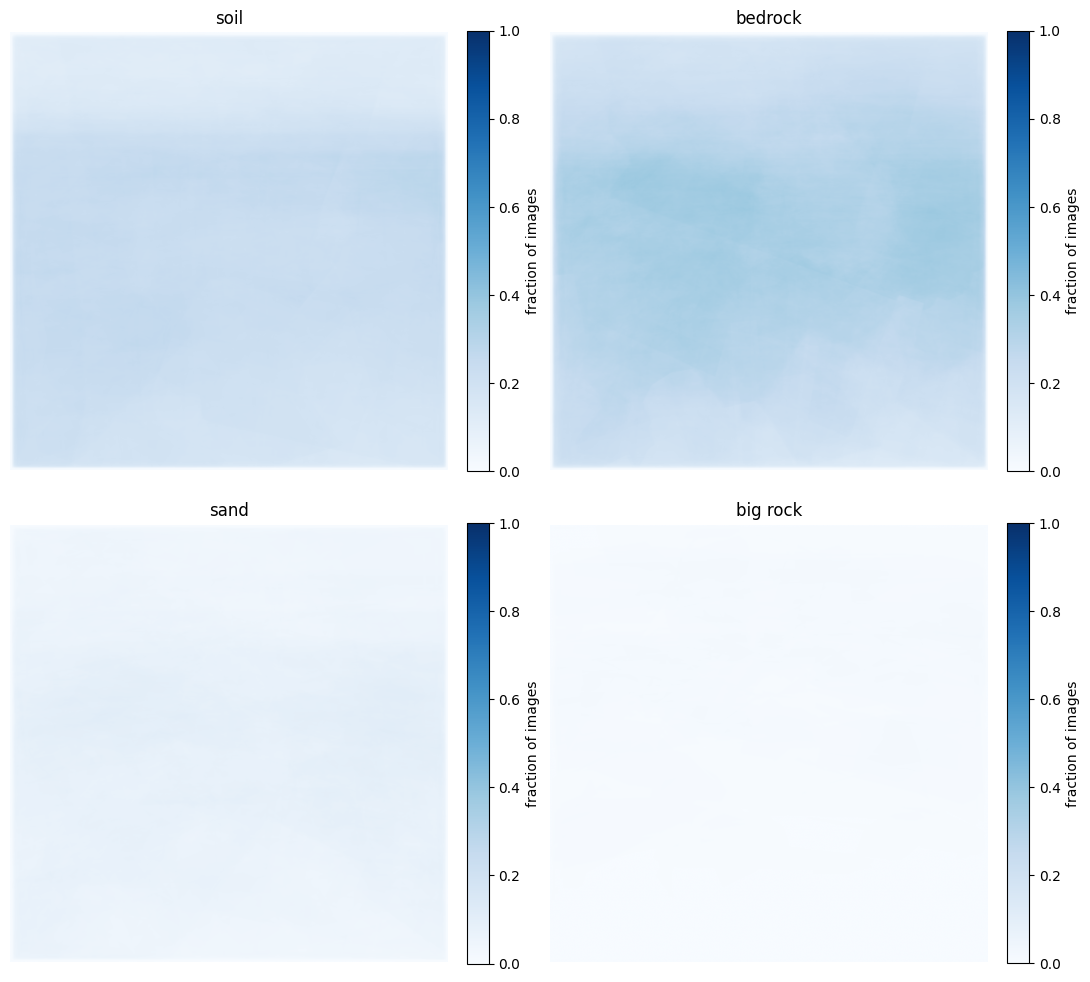

In [18]:
# Sanity checks
assert pixel_counts.sum() == labeled_total
assert (image_counts <= N).all()
assert heat.min() >= 0 and heat.max() <= 1

print(f"{N} training images, heatmap size {heat.shape[1]}x{heat.shape[2]}, {resized} masks resized")

# Class summary (excluding void/null pixels)
summary = pd.DataFrame({
    "class": CLASS_LABELS,
    "pixels": pixel_counts,
    "% of labeled pixels": (
        pixel_counts / max(labeled_total, 1) * 100
    ).round(2),
    "images with class": image_counts,
    "% of images": (image_counts / N * 100).round(1),
})
print(summary.to_string(index=False))

# Heatmaps: fraction of sampled images with each class at each position
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ax, c in zip(axes.flat, CLASSES):
  im = ax.imshow(heat[c], cmap="Blues", vmin=0, vmax=1, origin="upper")
  ax.set_title(CLASS_LABELS[c])
  ax.axis("off")
  fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="fraction of images")

plt.tight_layout()
plt.show()

# Task #6 and # 7 : Map Class to more Distrinct Colors

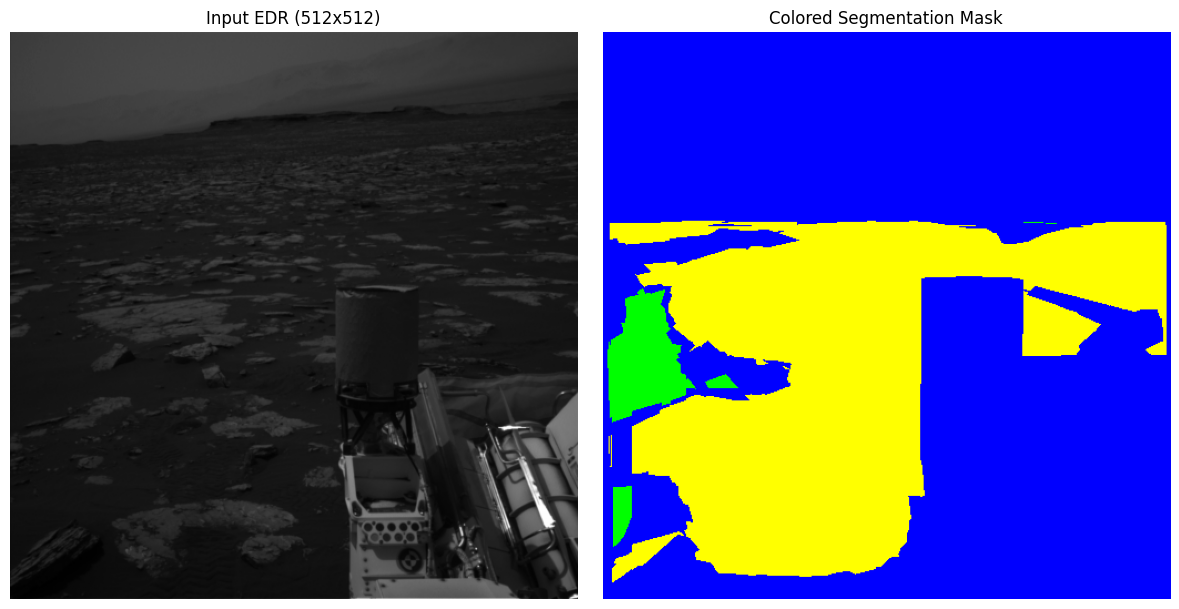

In [19]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

target_size = (512, 512)

color_map = {
    0 : [255, 0, 0],
    1 : [255, 255, 0],
    2 : [0, 255, 0],
    3 : [0, 255, 255],
    255 : [0, 0, 255],
}

class_names = {
    0 : "soil",
    1 : "bedrock",
    2 : "sand",
    3 : "Big Rock",
    255 :"void/null"
}

def load_and_resize (edr_path,label_path, target_size = target_size):
    edr_image = Image.open(edr_path).convert('L')
    edr_resized = edr_image.resize(target_size, resample = Image.BILINEAR)
    edr_arr = np.array(edr_resized)

    label_img = Image.open(label_path)
    label_resized = label_img.resize(target_size , resample = Image.NEAREST)
    label_arr = np.array(label_resized)

    return edr_arr, label_arr

def colorize_mask (label_arr):
    colored_mask = np.zeros((512, 512, 3), dtype = np.uint8)

    for class_ids, colors in color_map.items() :
        colored_mask[label_arr == class_ids] = colors
    return colored_mask

sample = df_kept.iloc[0]
sample_edr = os.path.join(MSL, sample['edr'])
sample_label = os.path.join(MSL, sample['label'])

edr_arr, label_arr = load_and_resize(sample_edr, sample_label)
colored_mask = colorize_mask(label_arr)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(edr_arr, cmap='gray')
axes[0].set_title(f"Input EDR ({target_size[0]}x{target_size[1]})")
axes[0].axis('off')

axes[1].imshow(colored_mask)
axes[1].set_title("Colored Segmentation Mask")
axes[1].axis('off')

plt.tight_layout()
plt.show()


In [20]:
import os
import zipfile
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')

local_extract_path = '/content/ai4mars_subset'
os.makedirs(local_extract_path, exist_ok=True)

zip_drive_path = '/content/drive/MyDrive/AI4Mars_Subset/ai4mars_subset.zip'
if len(os.listdir(local_extract_path)) == 0:
    print("Extracting subset from Google Drive... This is much faster than downloading the full dataset!")
    with zipfile.ZipFile(zip_drive_path, 'r') as zip_ref:
        zip_ref.extractall(local_extract_path)
    print("Extraction complete!")
else:
    print("Subset already extracted locally.")

MSL = local_extract_path
print("MSL root path is now set to:", MSL)

df_kept = pd.read_csv('/content/drive/MyDrive/AI4Mars_Subset/sample_split_filtered.csv')
print(f"Loaded metadata successfully. Total active samples: {len(df_kept)}")

Mounted at /content/drive
Extracting subset from Google Drive... This is much faster than downloading the full dataset!
Extraction complete!
MSL root path is now set to: /content/ai4mars_subset
Loaded metadata successfully. Total active samples: 839


# SegFormer: baseline vs. extra big-rock images

This section runs top to bottom with Run all. Steps:

1. Setup and settings
2. Load the data: subset train images, 125 min2 val images, and the other min2 images as a test set
3. Baseline: train on the subset
4. Big rock: scan the full training set and pick extra images with a lot of big rock
5. Big rock run: train on the subset plus the extra images
6. Compare both models on the test set

Val is used to pick the best epoch, so the final comparison uses the test set (min2 images the training never looked at).

Training is skipped if a finished run with the same settings is already saved in Drive. Set RETRAIN = True to train again anyway.

In [21]:
# Setup: install, imports, GPU check, Drive, Kaggle login

!pip install -q segmentation-models-pytorch kagglehub

import os, glob, json, time, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp
import kagglehub
from google.colab import drive, userdata

# Needs a GPU: Runtime > Change runtime type > T4 GPU
print("GPU available:", torch.cuda.is_available())
assert torch.cuda.is_available(), "No GPU. Switch the runtime to T4 GPU and run again."

drive.mount("/content/drive")

# Kaggle login from Colab secrets (KAGGLE_USERNAME and KAGGLE_KEY, notebook access turned on)
os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")

GPU available: True
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [22]:
# Settings. Change values here, not further down.

SEED = 42
SIZE = 512              # images and masks are resized to SIZE x SIZE (must be divisible by 32)
BATCH_SIZE = 16
LR = 0.0001
EPOCHS = 20             # same for both runs so they can be compared
NUM_CLASSES = 4
CLASS_NAMES = ["soil", "bedrock", "sand", "big rock"]
IGNORE = 255            # unlabeled pixels, skipped in the loss and in IoU

LABELED_MIN = 0.10      # an image needs at least this fraction of labeled pixels (same rule as Task 3)
BIG_ROCK_MIN = 0.10     # an extra image needs at least this fraction of big rock (out of labeled pixels)
N_ADD = 150             # number of extra big-rock images

RETRAIN = False         # True = train again even if a finished run is saved

# Data
SUBSET_ZIP = "/content/drive/MyDrive/AI4Mars_Subset/ai4mars_subset.zip"
SUBSET_ROOT = "/content/ai4mars_subset"

# Outputs, saved in Drive so they survive a runtime reset
BASELINE_DIR = "/content/drive/MyDrive/segformer_runs"          # baseline model and history, big rock scan and additions list
BIGROCK_DIR = "/content/drive/MyDrive/segformer_runs_bigrock"   # big rock model and history
os.makedirs(BASELINE_DIR, exist_ok=True)
os.makedirs(BIGROCK_DIR, exist_ok=True)
SCAN_CSV = f"{BASELINE_DIR}/big_rock_scan.csv"
ADDITIONS_CSV = f"{BASELINE_DIR}/big_rock_additions.csv"

device = "cuda"

In [23]:
# Get the data on disk

# Subset from the shared Drive zip: train images (with augmented copies) and 125 min2 val images
if not os.path.exists(f"{SUBSET_ROOT}/labels"):
    with zipfile.ZipFile(SUBSET_ZIP) as z:
        z.extractall(SUBSET_ROOT)

SUB_IMG_DIR = f"{SUBSET_ROOT}/images/edr"
SUB_TRAIN_MASKS = f"{SUBSET_ROOT}/labels/train"
SUB_VAL_MASKS = f"{SUBSET_ROOT}/labels/test/masked-gold-min2-100agree"

# Full dataset from Kaggle (downloads once per runtime, then reuses the copy on disk)
FULL_PATH = kagglehub.dataset_download("yash92328/ai4mars-terrainaware-autonomous-driving-on-mars")
FULL_MSL = glob.glob(os.path.join(FULL_PATH, "**", "msl"), recursive=True)[0]
FULL_EDR = os.path.join(FULL_MSL, "images", "edr")
FULL_TRAIN_MASKS = os.path.join(FULL_MSL, "labels", "train")
FULL_MIN2_MASKS = os.path.join(FULL_MSL, "labels", "test", "masked-gold-min2-100agree")

def png_names(folder):
    """Mask file names in a folder, without .png"""
    return {f[:-4] for f in os.listdir(folder) if f.endswith(".png")}

print("subset train masks:", len(png_names(SUB_TRAIN_MASKS)))
print("subset val masks:  ", len(png_names(SUB_VAL_MASKS)))
print("full train masks:  ", len(png_names(FULL_TRAIN_MASKS)))
print("full min2 masks:   ", len(png_names(FULL_MIN2_MASKS)))

Using Colab cache for faster access to the 'ai4mars-terrainaware-autonomous-driving-on-mars' dataset.
subset train masks: 714
subset val masks:   125
full train masks:   16064
full min2 masks:    322


In [24]:
# Pair each mask with its photo, and build the train / val / test lists

def pair_files(mask_dir, img_dir, names=None):
    """Return a sorted list of (photo path, mask path).
    Test masks end in _merged and their photos do not.
    If names is given, only masks with those names are used."""
    pairs, missing = [], []
    for name in sorted(png_names(mask_dir)):
        if names is not None and name not in names:
            continue
        img_path = os.path.join(img_dir, name.removesuffix("_merged") + ".JPG")
        if os.path.exists(img_path):
            pairs.append((img_path, os.path.join(mask_dir, name + ".png")))
        else:
            missing.append(name)
    if missing:
        print(f"skipped {len(missing)} masks with no photo in {mask_dir}, e.g. {missing[:2]}")
    return pairs

base_train_pairs = pair_files(SUB_TRAIN_MASKS, SUB_IMG_DIR)
val_pairs = pair_files(SUB_VAL_MASKS, SUB_IMG_DIR)

# Test set = min2 images that are not in val
val_names = png_names(SUB_VAL_MASKS)
assert val_names <= png_names(FULL_MIN2_MASKS), "val masks should all be min2 test masks"
test_names = png_names(FULL_MIN2_MASKS) - val_names
test_pairs = pair_files(FULL_MIN2_MASKS, FULL_EDR, names=test_names)

print("baseline train:", len(base_train_pairs))
print("val:  ", len(val_pairs))
print("test: ", len(test_pairs))

baseline train: 714
val:   125
test:  197


In [25]:
# Dataset and loaders

# ImageNet averages. The encoder was pretrained on images normalized this way.
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

class MarsDataset(Dataset):
    """Loads one photo and its mask, both resized to SIZE x SIZE."""
    def __init__(self, pairs):
        self.pairs = pairs

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, i):
        img_path, mask_path = self.pairs[i]
        # Photo: grayscale to 3 channels (the pretrained encoder expects 3), smooth resize
        img = Image.open(img_path).convert("RGB").resize((SIZE, SIZE), Image.BILINEAR)
        # Mask: nearest resize so class numbers stay exact
        mask = Image.open(mask_path).resize((SIZE, SIZE), Image.NEAREST)

        img = (np.array(img, dtype=np.float32) / 255.0 - MEAN) / STD
        img = torch.from_numpy(img).permute(2, 0, 1)            # (H, W, C) -> (C, H, W)
        mask = torch.from_numpy(np.array(mask, dtype=np.int64))  # class IDs as whole numbers
        return img, mask

def make_loader(pairs, shuffle):
    return DataLoader(MarsDataset(pairs), batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=2)

val_loader = make_loader(val_pairs, shuffle=False)
test_loader = make_loader(test_pairs, shuffle=False)

# Check one batch
imgs, masks = next(iter(val_loader))
print("images:", imgs.shape, imgs.dtype)
print("masks: ", masks.shape, masks.dtype)
print("mask values:", torch.unique(masks).tolist())   # should only be 0, 1, 2, 3, 255

images: torch.Size([16, 3, 512, 512]) torch.float32
masks:  torch.Size([16, 512, 512]) torch.int64
mask values: [0, 1, 255]


In [26]:
# Model, metrics, and training (shared by both runs)

def build_model(pretrained=True):
    torch.manual_seed(SEED)
    return smp.Segformer(
        encoder_name="mit_b0",
        encoder_weights="imagenet" if pretrained else None,
        classes=NUM_CLASSES,
    ).to(device)

loss_fn = nn.CrossEntropyLoss(ignore_index=IGNORE)

def count_pixels(preds, masks):
    """Confusion matrix counts for one batch: row = true class, column = predicted class.
    Unlabeled pixels are skipped."""
    valid = masks != IGNORE
    idx = masks[valid] * NUM_CLASSES + preds[valid]
    return torch.bincount(idx, minlength=NUM_CLASSES ** 2).reshape(NUM_CLASSES, NUM_CLASSES)

def iou_per_class(cm):
    """IoU for each class from a confusion matrix (numpy). nan if a class never appears."""
    inter = np.diag(cm).astype(float)
    union = cm.sum(axis=0) + cm.sum(axis=1) - inter
    with np.errstate(invalid="ignore", divide="ignore"):
        return inter / union

def mean_iou(cm):
    """Average IoU over the classes that appear."""
    return float(np.nanmean(iou_per_class(cm)))

def run_epoch(model, loader, optimizer=None):
    """One pass over loader. Trains if an optimizer is given, otherwise only evaluates.
    Returns (average loss, mIoU, confusion matrix)."""
    training = optimizer is not None
    model.train(training)
    total_loss = 0.0
    cm = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long, device=device)

    for imgs, masks in loader:
        imgs, masks = imgs.to(device), masks.to(device)
        with torch.set_grad_enabled(training):
            logits = model(imgs)
            loss = loss_fn(logits, masks)   # CrossEntropyLoss applies softmax internally
        if training:
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        total_loss += loss.item()
        preds = logits.softmax(dim=1).argmax(dim=1)   # most likely class per pixel
        cm += count_pixels(preds, masks)

    cm = cm.cpu().numpy()
    return total_loss / len(loader), mean_iou(cm), cm

def run_settings(train_pairs):
    """Settings that define a run. A saved run is reused only if these match."""
    return {"lr": LR, "epochs": EPOCHS, "batch_size": BATCH_SIZE, "size": SIZE,
            "seed": SEED, "n_train": len(train_pairs), "n_val": len(val_pairs)}

def train_run(name, train_pairs, save_dir):
    """Train a fresh model, keep the epoch with the best val mIoU, and save everything to save_dir.
    Skips training if save_dir already has a finished run with the same settings."""
    weights_file = f"{save_dir}/best_segformer.pt"
    history_file = f"{save_dir}/history.json"
    info_file = f"{save_dir}/run_info.json"   # written only when a run finishes
    settings = run_settings(train_pairs)

    if not RETRAIN and os.path.exists(info_file) and os.path.exists(weights_file):
        with open(info_file) as f:
            saved = json.load(f)
        if saved == settings:
            print(f"{name}: finished run with the same settings found in {save_dir}, skipping training")
            with open(history_file) as f:
                return json.load(f)
        print(f"{name}: saved run has different settings, training again")

    if os.path.exists(info_file):
        os.remove(info_file)   # so a half-finished run is never mistaken for a finished one

    model = build_model()
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    train_loader = make_loader(train_pairs, shuffle=True)
    history = {"train_loss": [], "val_loss": [], "train_miou": [], "val_miou": []}
    best = -1.0

    print(f"{name}: training on {len(train_pairs)} images for {EPOCHS} epochs")
    for epoch in range(1, EPOCHS + 1):
        start = time.time()
        tr_loss, tr_miou, _ = run_epoch(model, train_loader, optimizer)
        va_loss, va_miou, _ = run_epoch(model, val_loader)

        history["train_loss"].append(tr_loss)
        history["val_loss"].append(va_loss)
        history["train_miou"].append(tr_miou)
        history["val_miou"].append(va_miou)

        if va_miou > best:
            best = va_miou
            torch.save(model.state_dict(), weights_file)
        with open(history_file, "w") as f:
            json.dump(history, f)

        print(f"epoch {epoch} | train loss {tr_loss:.3f} miou {tr_miou:.3f} | "
              f"val loss {va_loss:.3f} miou {va_miou:.3f} | {time.time() - start:.0f}s")

    with open(info_file, "w") as f:
        json.dump(settings, f)
    best_epoch = int(np.argmax(history["val_miou"])) + 1
    print(f"{name}: best val mIoU {best:.3f} at epoch {best_epoch}")
    return history

def plot_run(name, history, n_train, save_dir):
    """Loss and mIoU vs epochs for one run, with the settings in red. Returns the file names."""
    epochs = range(1, len(history["train_loss"]) + 1)
    best_epoch = int(np.argmax(history["val_miou"])) + 1
    settings = (f"SegFormer mit_b0 (ImageNet) | Adam lr={LR} | batch {BATCH_SIZE} | {SIZE}x{SIZE} | "
                f"{n_train} train images\n"
                f"CrossEntropy (ignore 255) | val: {len(val_pairs)} min2 images | {len(epochs)} epochs | "
                f"best val mIoU {max(history['val_miou']):.3f} @ epoch {best_epoch}")
    filenames = []
    for key, label in [("loss", "Loss"), ("miou", "mIoU")]:
        plt.figure(figsize=(9, 5.5))
        plt.plot(epochs, history[f"train_{key}"], marker="o", label="train")
        plt.plot(epochs, history[f"val_{key}"], marker="o", label="val")
        plt.xlabel("Epoch")
        plt.ylabel(label)
        plt.title(f"SegFormer {name}: {label} vs Epochs")
        plt.legend()
        plt.grid(alpha=0.3)
        plt.figtext(0.5, 0.01, settings, ha="center", color="red", fontsize=9)
        plt.tight_layout(rect=[0, 0.08, 1, 1])
        filename = f"segformer_{name}_{key}.png"
        plt.savefig(filename, dpi=150)
        plt.savefig(f"{save_dir}/{filename}", dpi=150)
        plt.show()
        filenames.append(filename)
    return filenames

print("ready")

ready


# Baseline
Trains on the subset only.

config.json:   0%|          | 0.00/135 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 14.3MB            

model.safetensors: downloading bytes:           |  0.00B            

baseline: training on 714 images for 20 epochs
epoch 1 | train loss 0.507 miou 0.496 | val loss 0.187 miou 0.673 | 52s
epoch 2 | train loss 0.289 miou 0.609 | val loss 0.124 miou 0.692 | 48s
epoch 3 | train loss 0.226 miou 0.663 | val loss 0.175 miou 0.682 | 49s
epoch 4 | train loss 0.182 miou 0.688 | val loss 0.144 miou 0.690 | 50s
epoch 5 | train loss 0.156 miou 0.747 | val loss 0.116 miou 0.705 | 50s
epoch 6 | train loss 0.143 miou 0.766 | val loss 0.159 miou 0.685 | 52s
epoch 7 | train loss 0.146 miou 0.770 | val loss 0.148 miou 0.691 | 50s
epoch 8 | train loss 0.142 miou 0.771 | val loss 0.142 miou 0.696 | 50s
epoch 9 | train loss 0.108 miou 0.808 | val loss 0.140 miou 0.694 | 52s
epoch 10 | train loss 0.103 miou 0.838 | val loss 0.164 miou 0.690 | 49s
epoch 11 | train loss 0.084 miou 0.853 | val loss 0.166 miou 0.690 | 50s
epoch 12 | train loss 0.077 miou 0.863 | val loss 0.153 miou 0.693 | 52s
epoch 13 | train loss 0.064 miou 0.887 | val loss 0.164 miou 0.691 | 49s
epoch 14 | tr

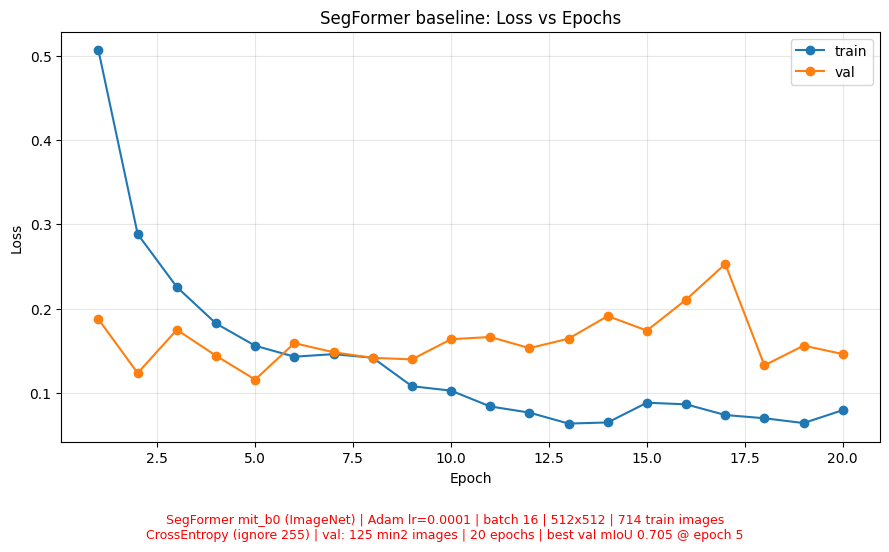

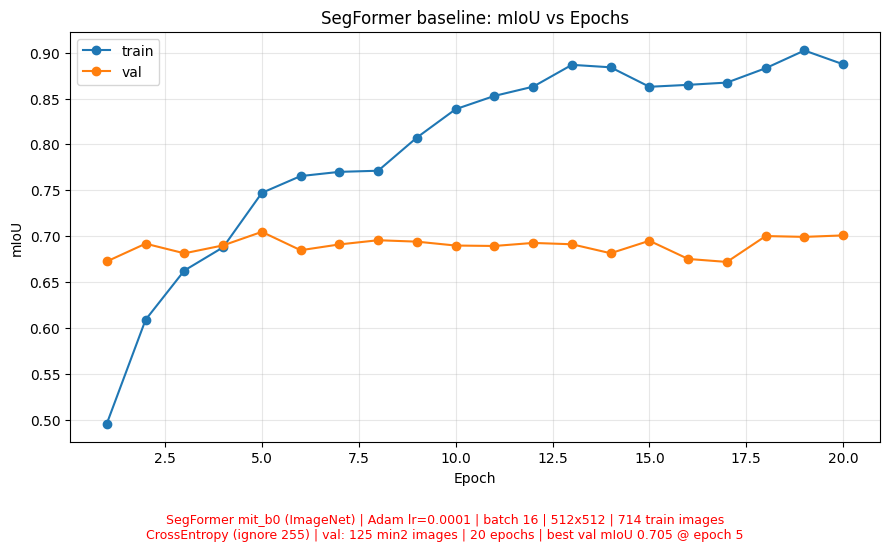

In [27]:
# Train the baseline (about 45 s per epoch on a T4)

base_history = train_run("baseline", base_train_pairs, BASELINE_DIR)
base_plots = plot_run("baseline", base_history, len(base_train_pairs), BASELINE_DIR)

# Big rock: pick extra training images
Big rock is about 1.4% of labeled pixels in the subset, and the baseline almost never predicts it. This section finds full-dataset training images with a lot of big rock that are not already in the subset.

In [28]:
# Which full-dataset images are already in the subset?
# Subset files can have augmentation suffixes (for example _brightened or _flipped_brightened),
# so suffixes are removed until the name matches a real dataset name.

full_names = png_names(FULL_TRAIN_MASKS)

def original_name(n):
    while n not in full_names and "_" in n:
        n = n.rsplit("_", 1)[0]
    return n

in_subset = {original_name(n) for n in png_names(SUB_TRAIN_MASKS)}
assert in_subset <= full_names, "some subset names did not match the full dataset"
print("unique images already in the subset:", len(in_subset))

unique images already in the subset: 476


In [29]:
# Measure big rock in every full training mask.
# This takes a few minutes, so the result is saved to Drive and loaded next time.

if os.path.exists(SCAN_CSV):
    scan = pd.read_csv(SCAN_CSV)
    print("loaded saved scan:", SCAN_CSV)
else:
    rows = []
    for i, n in enumerate(sorted(full_names)):
        label = np.array(Image.open(os.path.join(FULL_TRAIN_MASKS, n + ".png")))
        counts = np.bincount(label.ravel(), minlength=256)   # counts[v] = number of pixels with value v
        labeled = label.size - counts[IGNORE]
        rows.append({
            "name": n,
            "labeled_frac": labeled / label.size,
            "big_rock_px": int(counts[3]),
            "big_rock_frac": counts[3] / max(labeled, 1),   # out of labeled pixels
            "has_edr": os.path.exists(os.path.join(FULL_EDR, n + ".JPG")),
        })
        if i % 2000 == 0:
            print(f"{i} / {len(full_names)}")
    scan = pd.DataFrame(rows)
    scan.to_csv(SCAN_CSV, index=False)

# Recomputed every time so it always matches the current subset
scan["in_subset"] = scan["name"].isin(in_subset)

sub = scan[scan.in_subset]
cands = scan[~scan.in_subset & scan.has_edr & (scan.labeled_frac >= LABELED_MIN)]
print("subset images with any big rock:", (sub.big_rock_px > 0).sum(), "of", len(sub))
print("candidates:", len(cands), "| with any big rock:", (cands.big_rock_px > 0).sum())
for t in [0.01, 0.05, 0.10, 0.20, 0.30]:
    print(f"  big rock >= {t:.0%} of labeled pixels: {(cands.big_rock_frac >= t).sum()} images")

# How much big rock the val and test sets have (few images means a noisy big rock IoU)
def big_rock_in(pairs):
    n_imgs = n_px = 0
    for _, mask_path in pairs:
        c = int((np.array(Image.open(mask_path)) == 3).sum())
        n_imgs += c > 0
        n_px += c
    return n_imgs, n_px

for split, pairs in [("val", val_pairs), ("test", test_pairs)]:
    n_imgs, n_px = big_rock_in(pairs)
    print(f"{split}: {n_imgs} of {len(pairs)} images have big rock ({n_px:,} pixels at full size)")

loaded saved scan: /content/drive/MyDrive/segformer_runs/big_rock_scan.csv
subset images with any big rock: 77 of 476
candidates: 14847 | with any big rock: 2080
  big rock >= 1% of labeled pixels: 1318 images
  big rock >= 5% of labeled pixels: 700 images
  big rock >= 10% of labeled pixels: 464 images
  big rock >= 20% of labeled pixels: 254 images
  big rock >= 30% of labeled pixels: 150 images
val: 6 of 125 images have big rock (17,796 pixels at full size)
test: 14 of 197 images have big rock (111,861 pixels at full size)


In [30]:
# Pick the extra images: a random sample (fixed seed) of candidates with at least BIG_ROCK_MIN big rock.
# Random instead of "most big rock first", because the top images are mostly close-ups of one boulder.

PX = 1024 * 1024   # full-size masks are 1024 x 1024
pool = cands[cands.big_rock_frac >= BIG_ROCK_MIN].sort_values("name")   # sorted so the picks are the same everywhere
assert len(pool) >= N_ADD, f"only {len(pool)} candidates, lower N_ADD or BIG_ROCK_MIN"

base_rock = sub.big_rock_px.sum()
base_lab = (sub.labeled_frac * PX).sum()
print(f"subset now: big rock = {base_rock / base_lab:.2%} of labeled pixels ({len(sub)} unique images)")
for n in sorted({50, 100, 150, 200, 300, N_ADD}):
    if n > len(pool):
        continue
    pick = pool.sample(n=n, random_state=SEED)
    share = (base_rock + pick.big_rock_px.sum()) / (base_lab + (pick.labeled_frac * PX).sum())
    print(f"  add {n:>3}: big rock = {share:.2%}")

picked = pool.sample(n=N_ADD, random_state=SEED).sort_values("name").copy()
picked["edr"] = "images/edr/" + picked["name"] + ".JPG"       # same path style as sample_split_filtered.csv
picked["label"] = "labels/train/" + picked["name"] + ".png"
picked = picked[["name", "edr", "label", "labeled_frac", "big_rock_frac", "big_rock_px"]]

assert len(picked) == N_ADD
assert picked["name"].is_unique
assert not picked["name"].isin(in_subset).any()
assert (picked["labeled_frac"] >= LABELED_MIN).all()
assert (picked["big_rock_frac"] >= BIG_ROCK_MIN).all()

picked.to_csv(ADDITIONS_CSV, index=False)
picked.to_csv("big_rock_additions.csv", index=False)
print(f"picked {len(picked)} images | median big rock {picked.big_rock_frac.median():.1%} | saved to {ADDITIONS_CSV}")

extra_pairs = [(os.path.join(FULL_EDR, n + ".JPG"), os.path.join(FULL_TRAIN_MASKS, n + ".png"))
               for n in picked["name"]]
assert all(os.path.exists(p) for pair in extra_pairs for p in pair)
bigrock_train_pairs = base_train_pairs + extra_pairs
print("big rock run train images:", len(bigrock_train_pairs))

subset now: big rock = 1.41% of labeled pixels (476 unique images)
  add  50: big rock = 3.52%
  add 100: big rock = 5.35%
  add 150: big rock = 6.90%
  add 200: big rock = 8.38%
  add 300: big rock = 10.17%
picked 150 images | median big rock 22.4% | saved to /content/drive/MyDrive/segformer_runs/big_rock_additions.csv
big rock run train images: 864


# Big rock run
Same settings as the baseline, trained on the subset plus the extra big-rock images.

bigrock: training on 864 images for 20 epochs
epoch 1 | train loss 0.561 miou 0.526 | val loss 0.237 miou 0.643 | 62s
epoch 2 | train loss 0.330 miou 0.678 | val loss 0.151 miou 0.689 | 61s
epoch 3 | train loss 0.274 miou 0.722 | val loss 0.216 miou 0.651 | 61s
epoch 4 | train loss 0.242 miou 0.769 | val loss 0.166 miou 0.682 | 61s
epoch 5 | train loss 0.211 miou 0.791 | val loss 0.183 miou 0.669 | 61s
epoch 6 | train loss 0.178 miou 0.821 | val loss 0.184 miou 0.673 | 60s
epoch 7 | train loss 0.160 miou 0.838 | val loss 0.171 miou 0.685 | 61s
epoch 8 | train loss 0.155 miou 0.847 | val loss 0.134 miou 0.700 | 61s
epoch 9 | train loss 0.134 miou 0.861 | val loss 0.132 miou 0.698 | 60s
epoch 10 | train loss 0.123 miou 0.870 | val loss 0.162 miou 0.679 | 60s
epoch 11 | train loss 0.114 miou 0.870 | val loss 0.180 miou 0.686 | 60s
epoch 12 | train loss 0.093 miou 0.899 | val loss 0.190 miou 0.686 | 60s
epoch 13 | train loss 0.083 miou 0.911 | val loss 0.143 miou 0.704 | 60s
epoch 14 | tra

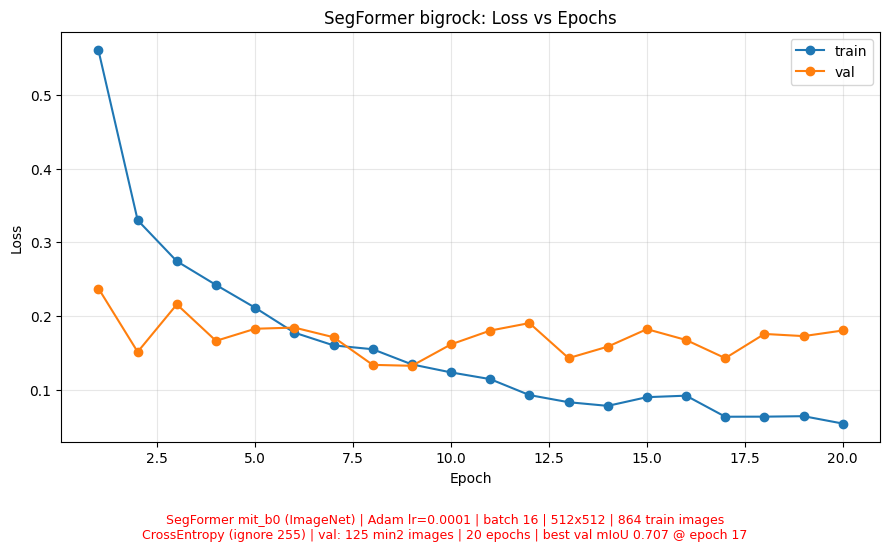

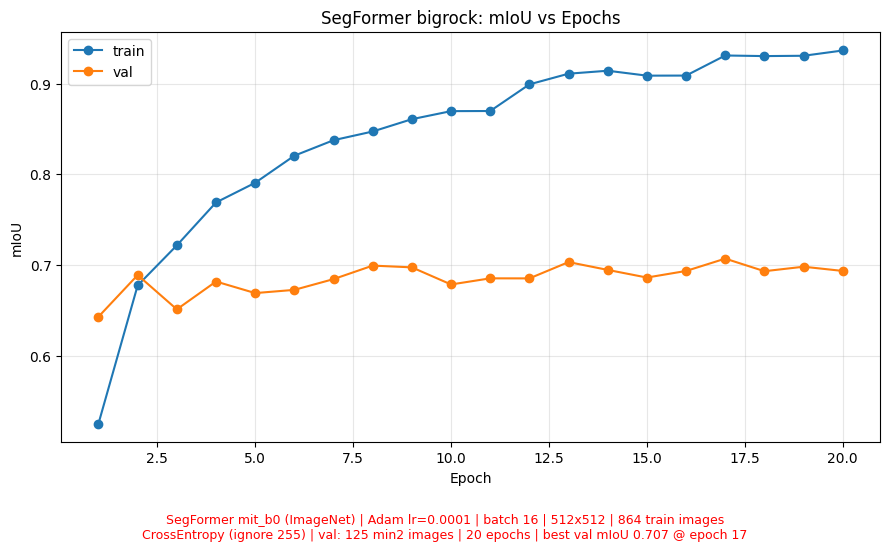

In [31]:
# Train with the extra big-rock images (about 55 s per epoch on a T4)

bigrock_history = train_run("bigrock", bigrock_train_pairs, BIGROCK_DIR)
bigrock_plots = plot_run("bigrock", bigrock_history, len(bigrock_train_pairs), BIGROCK_DIR)

# Compare both models on the test set
Each model is loaded from its best epoch and scored on the test images (min2 images not used for val).

Test IoU (197 min2 images)
          baseline  bigrock  change
soil         0.922    0.941   0.020
bedrock      0.850    0.853   0.003
sand         0.853    0.896   0.043
big rock     0.056    0.099   0.043
mIoU         0.670    0.697   0.027
big rock pixels in test (at 512x512): 27,952


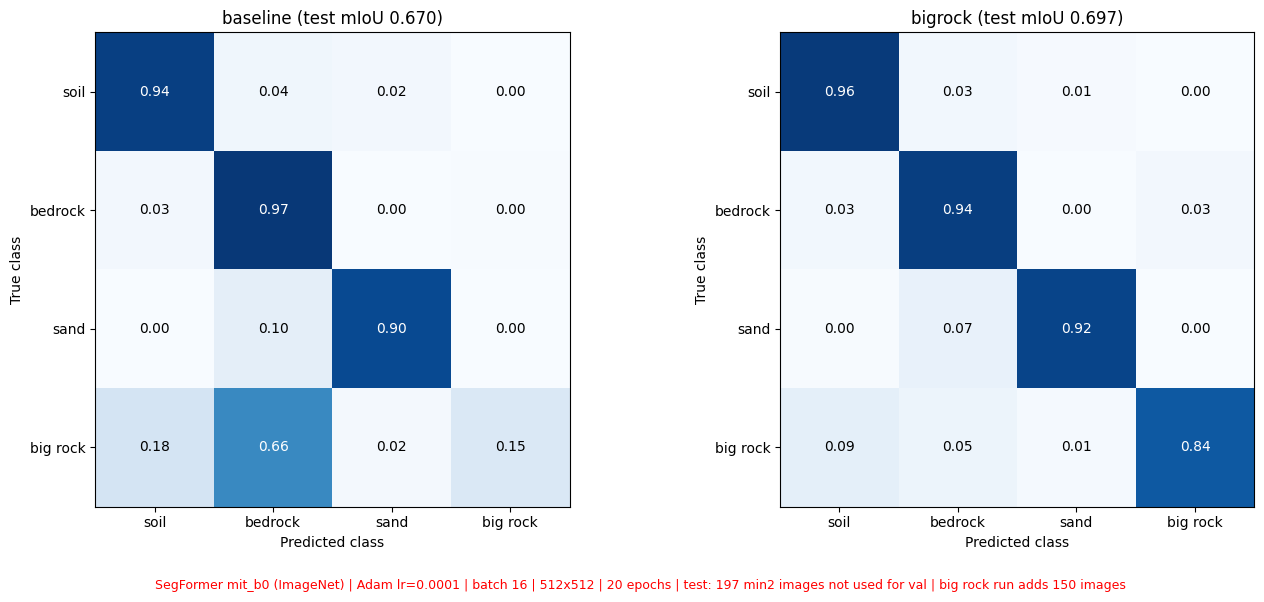

In [32]:
# Per-class IoU and confusion matrices on the test set

runs = [("baseline", BASELINE_DIR), ("bigrock", BIGROCK_DIR)]
test_cms = {}
for name, folder in runs:
    model = build_model(pretrained=False)
    model.load_state_dict(torch.load(f"{folder}/best_segformer.pt", map_location=device))
    model.eval()
    with torch.no_grad():
        _, _, test_cms[name] = run_epoch(model, test_loader)

table = pd.DataFrame({name: iou_per_class(cm) for name, cm in test_cms.items()}, index=CLASS_NAMES)
table.loc["mIoU"] = [mean_iou(cm) for cm in test_cms.values()]
table["change"] = table["bigrock"] - table["baseline"]
print(f"Test IoU ({len(test_pairs)} min2 images)")
print(table.round(3).to_string())
print("big rock pixels in test (at 512x512):", f"{test_cms['baseline'][3].sum():,}")

# Confusion matrices as row percentages (each row sums to 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, cm) in zip(axes, test_cms.items()):
    pct = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES)
    ax.set_yticks(range(NUM_CLASSES), CLASS_NAMES)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.set_title(f"{name} (test mIoU {mean_iou(cm):.3f})")
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, f"{pct[i, j]:.2f}", ha="center", va="center",
                    color="white" if pct[i, j] > 0.5 else "black")
fig.text(0.5, 0.01, f"SegFormer mit_b0 (ImageNet) | Adam lr={LR} | batch {BATCH_SIZE} | {SIZE}x{SIZE} | "
                    f"{EPOCHS} epochs | test: {len(test_pairs)} min2 images not used for val | "
                    f"big rock run adds {N_ADD} images",
         ha="center", color="red", fontsize=9)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig("segformer_confusion_matrices.png", dpi=150)
plt.savefig(f"{BIGROCK_DIR}/segformer_confusion_matrices.png", dpi=150)
plt.show()

In [33]:
# Download the graphs and the additions list (the browser may ask to allow multiple downloads)

from google.colab import files

for f in base_plots + bigrock_plots + ["segformer_confusion_matrices.png", "big_rock_additions.csv"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (2 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>